# MIL-CREDA proof of concept: summary of the toy-set verdicts

This notebook trains nothing. It only reads results already saved under `MIL-CREDA/Results/`
and puts the proof of concept (PoC) in one place:

- `PoC_Conditions/verdicts.json` (run 3),
- `PoC_K2K3/verdicts.json` (run 4, corrected tests),
- `PoC_K2K3_v2/scenario_analysis.md` (EEG-grounded scenario analysis),
- `PoC_K2K3_v3/{preregistration,verdicts}.json` and `PoC_K2K3_v3/cache/*.json` (run 6),
- `discussion.json` (the verdicts the dashboard shows).

## Purpose and the operator's PoC criterion

The PoC asks one question per hypothesis: **on a toy set built to contain the condition the
hypothesis needs, does the mechanism do what the proposal says it does?** A hypothesis gets a
toy-set green light when its pre-registered test passes there. The toy set is `rollo` with the
BatchNorm MLP encoder, 30 seeds, Wilcoxon signed-rank tests paired over seeds, rules written
before each run. A toy-set green light is not an EEG result: every EEG verdict stays pending
until the full experiments run on BALLADEER.

In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()


In [2]:
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

RESULTS = ROOT / "MIL-CREDA" / "Results"
RUN3 = json.loads((RESULTS / "PoC_Conditions" / "verdicts.json").read_text(encoding="utf-8"))
RUN4 = json.loads((RESULTS / "PoC_K2K3" / "verdicts.json").read_text(encoding="utf-8"))
RUN6_PRE = json.loads((RESULTS / "PoC_K2K3_v3" / "preregistration.json").read_text(encoding="utf-8"))
RUN6 = json.loads((RESULTS / "PoC_K2K3_v3" / "verdicts.json").read_text(encoding="utf-8"))
DISCUSSION = json.loads((RESULTS / "discussion.json").read_text(encoding="utf-8"))
CACHE = [json.loads(p.read_text(encoding="utf-8"))
         for p in sorted((RESULTS / "PoC_K2K3_v3" / "cache").glob("*.json"))]
FIGURES = RESULTS / "PoC_K2K3_v3"
print(f"run 6 cache entries: {len(CACHE)}; discussion stage: {DISCUSSION['stage']}, "
      f"protocol: {DISCUSSION['protocol']}")

run 6 cache entries: 60; discussion stage: poc, protocol: experiments-plan-experimental-mil-creda-sobre-balladeer-v55.md


## What each run tested, and why the earlier K2/K3 runs had no room

Facts from the task log (`odd/tasks/pipeline-phase-review.md`, L112 and L125-L132):

- **Run 3** (`PoC_Conditions`, L112): task-level adaptation, K1 (attention down-weights
  contaminated windows, artifact and donor families), K2 (partner separation) and the K3 ladder
  (TGL vs TG, TL, TGL-NC) on clean and artifact bags. Task and K1-artifact passed; K2 and K3 did
  not.
- **Run 4** (`PoC_K2K3`, L125): the corrected tests. The task contrast is taken against the
  BN-matched floor (AdaBN) instead of a floor that kept source BatchNorm statistics, and the
  K2/K3 ladder adds gating measurements. Accuracies are identical to run 3. The gates show the
  mechanisms had no room: the attention entropy ratio pi is 0.987 (clean) / 0.975 (artifact)
  against the gate < 0.9, and the start partner kernel rank is 0.062 / 0.083 against the gate
  >= 0.5 (about chance, 1/16). Same-class bags were already mutually close in the embedding, so
  the local push had nothing to do: K2b and K3b are inconclusive, not refuted.
- **Run 5** (EEG-grounded scenario, L128): the toy was calibrated to BALLADEER (subject identity
  explains 0.43-0.65 of window variance against 0.0001-0.03 for the class; subject signature
  0.15 of the class separation matches the level arm). The gate check on two seeds failed
  again, so no battery ran, and the K3a artifact rate was fixed at 0.4 by the pre-declared rule.
- **Run 6** (`PoC_K2K3_v3`, L129-L132): the test was redesigned with the operator (L129). K2 is
  the push of each target bag toward its own source partner, with versus without the local
  term, valid only where partners start misaligned; K3 is the ladder under a subject-specific
  residual (shift 2.0, noise 0.05) that the global term cannot remove. The room gate (median
  own-partner distance over same-class spread >= 1.0, source accuracy >= 0.85, L131) held:
  1.05 clean, 1.14 artifact, source accuracy 0.93.

### The EEG-grounded scenario analysis (run 5), as saved

In [3]:
display(Markdown((RESULTS / "PoC_K2K3_v2" / "scenario_analysis.md").read_text(encoding="utf-8")))

## 0. Scenario analysis: what the toy must imitate from BALLADEER EEG

All EEG numbers are read from disk. Sources: `MIL-CREDA/Data/processed/manifest.csv` and the per-record `signals/*.npz` of the implementation repository (non-excluded records only, i.e. no undetermined subjects, no EPOC+), `MIL-CREDA/Results/separability/{summary.json,tables/*.csv}`, and the protocol `experiments/experiments-plan-experimental-mil-creda-sobre-balladeer-v55.md` §2-§6.

The window features for (b) are the log of the channel-mean band power in 0.5-4, 4-8, 8-13, 13-30 and 30-45 Hz (Welch, 2 s segments), with at most 150 windows sampled per bag. That makes them device-agnostic: 5 features per window. Scripts: `eeg.py`, `pct.py`, `toy.py`, `cal.py` (scratch, not committed).

### 0.1 EEG circumstances

**(a) Bag size and subjects.** A bag is one subject × condition (§3.2).

| condition | bags | ADHD / control | windows per bag (median, min-max) |
|---|---|---|---|
| Slackline-L1/CGX | 123 | 80 / 43 | 75 (75-76) |
| Slackline-L6/CGX | 123 | 79 / 44 | 75 (75-76) |
| Slackline-L11/CGX | 123 | 79 / 44 | 75 (75-282) |
| Robots/EMOTIV (EPOC X) | 60 | 29 / 31 | 72 (68-132) |
| Cognifit/EMOTIV (EPOC X) | 61 | 30 / 31 | 529 (406-809) |

Per transfer and rotation (`assignment_sizes.csv`): level arm ≈ 63 subjects per side, of which ≈ 47 are non-test; task arm 33 per side (≈ 25 non-test); device arm 75 / 52.

**(b) Subject identity against class signal.** Columns:
- η²: the fraction of window-level variance explained by subject or by class (median over the 5 bands).
- subject ID: a bag's first half of windows matched to its own second half, nearest centroid.
- class AUC: 5-fold logistic regression on bag means.

| condition | η² subject | η² class | subject ID (chance) | class AUC |
|---|---|---|---|---|
| L1/CGX | 0.62 | 0.0001 | 0.28 (0.008) | 0.45 |
| L6/CGX | 0.63 | 0.017 | 0.34 (0.008) | 0.58 |
| L11/CGX | 0.65 | 0.020 | 0.28 (0.008) | 0.57 |
| Robots/EMOTIV | 0.43 | 0.030 | 0.50 (0.017) | 0.73 |
| Cognifit/EMOTIV | 0.54 | 0.004 | 0.48 (0.016) | 0.64 |

- Subject identity explains 20 to over 1000 times more window variance than the class does, and the class signal in band power is weak (AUC 0.45-0.73). This is measured, not assumed.
- What K2 needs, though, is the fingerprint ACROSS conditions. The relevant reading is the own-partner percentile: for each common subject, the fraction of other subjects whose other-condition bag lies farther away than the subject's own (bag means, per-domain standardized; 0.5 is chance, 1 is always nearest).

| pair (arm) | common subjects | percentile, all | percentile, within class | own bag nearest (chance) |
|---|---|---|---|---|
| L1 / L11 (level, core) | 119 | 0.795 | 0.789 | 0.126 (0.008) |
| Cognifit / Robots (task) | 55 | 0.734 | 0.723 | 0.036 (0.018) |
| L6 / Robots (device) | 56 | 0.644 | 0.647 | 0.036 (0.018) |

So the EEG cross-condition fingerprint is real but moderate in the level arm (the own bag is nearest for 1 subject in 8), weak in the task arm, and close to chance in the device arm.

**(c) Domain shift.** The protocol's domain classifier works on band power with subject-disjoint sides and is grouped by subject (§5, `separability.csv`): level L1-L11 AUC 0.636, task 0.665, device 0.978. The other level pairs (0.508, 0.445) are at chance.

**(d) Marked windows (§6.1: integrity per §2.3 or bad contact per §2.5).** Columns are the per-bag fraction of marked windows.

| condition | median | Q25-Q75 | bags with any marked | mean over bags with any |
|---|---|---|---|---|
| L1, L6, L11/CGX | 0 | 0-0 | 0 of 369 | n/a |
| Robots/EMOTIV | 0.043 | 0-1.0 | 65 % | 0.63 |
| Cognifit/EMOTIV | 0.319 | 0.002-1.0 | 77 % | 0.59 |

- CGX has no contact indicator, and its integrity marks are 0 in every non-excluded bag. The marked-window contrast of §6.1 therefore has no subject to compute on in the level arm, which is where K1's success criterion is evaluated. This is a protocol issue for the parent; the toy does not change it.
- On EMOTIV the fraction is bimodal: many bags are clean and many are marked in every window. A marked window means bad contact on at least one of 14 electrodes, not a corrupted window.

**(e) Class balance.** CGX is 65 % ADHD (80 / 43); EPOC X is balanced (30 / 31).

### 0.2 The toy measured with the same instruments (rollo, CONDITIONS_SCALE, RUN3, seeds 10-11)

| reading | toy | EEG target |
|---|---|---|
| bag size | 50 | 72-75 (CGX, Robots); 529 (Cognifit) |
| bags per class per domain (train) | 39 (16) | ≈ 40-80 ADHD / 22-44 control per condition |
| classes | 3, balanced | 2; 65 % ADHD on CGX |
| class AUC, bag means, linear | 0.90-0.91 | 0.45-0.73 |
| domain AUC, raw bag means | 1.00 (any rotation; the 3σ translation of `perturbar` dominates) | level 0.64, task 0.67, device 0.98 |
| domain AUC, per-domain standardized | 0.39-0.45 (the rotation preserves Σ) | n/a |
| own-partner percentile within class, no signature, rotation 25 | 0.725 | level 0.789, task 0.723, device 0.647 |

### 0.3 Calibration

- **Subject signature.** The knob is expressed as a multiple of the source's between-class separation. Scan at rotation 25, within-class own-partner percentile over the 16 train bags (mean of seeds 10 and 11):

  | multiple | 0 | 0.05 | 0.10 | 0.13 | 0.15 | 0.20 | 0.5 | 1.0 |
  |---|---|---|---|---|---|---|---|---|
  | percentile | 0.725 | 0.733 | 0.758 | 0.776 | **0.789** | 0.817 | 0.929 | 0.975 |

  - The level arm (0.789) is matched at **0.15 × separation**, an amplitude of about 0.59, which is below the within-bag spread of about 3.45.
  - The task arm (0.723) is matched with no signature at all.
  - The device arm (0.647) lies below anything the toy reaches without adding noise.
  - The run-5 first try (amplitude 3.7-3.99, about 0.93-0.99 × separation) made the toy far more identifiable than EEG.
- **Shift.** The only shift knob is `rotation_degrees`; the 3σ translation is fixed inside `CREDA.toy_experiment.perturbar`. In raw terms the toy shift is therefore device-like (domain AUC 1.0 against 0.978) at every rotation, while its cross-domain subject identity is level-like. Level-like shift size (AUC about 0.64) is not reachable with the declared knobs. Rotation stays at run 3's 25.
- **Artifact rate.** 0.2, 0.3 and 0.4 all lie inside the observed EMOTIV range, so none is excluded by EEG. The EEG distribution is bimodal per bag, which a fixed per-bag rate does not imitate, and the CGX level arm has no marked windows at all. The toy artifact (noise of 1 esc on every coordinate) is stronger than a single bad electrode out of 14.
- **Bag size, class balance, class count.** Kept at 50 points per bag, 3 balanced classes. Bag size enters only the consensus estimate, and imbalance enters none of the K2/K3 mechanisms. A 75-point scale would cost about 1.5× compute and break comparability with runs 3-4.
- **Class signal.** The toy class is much stronger than EEG's (0.90 against 0.45-0.73). Weakening it is outside the declared knobs. Consequently the routing error at the start of phase 2 is driven by the shift (0.667 with the target collapsed onto one class), not by a weak class.

### 0.4 What the calibrated toy can and cannot settle

- **Can settle:**
  - K3a as an aggregation question on artifact bags at a declared rate.
  - K3b and K3c accuracy contrasts under a device-sized raw shift with level-like subject identity.
  - Whether the local term raises the kernel-space partner rank during phase 2 (rank at the end against rank at the start, TGL against TG).
- **Cannot settle:**
  - K2b and K3b under the pre-registered gates. In input space the toy already carries EEG-level subject identity (0.79), yet the frozen phase-1 kernel puts the partner at chance (start rank 0.02-0.08 against a 0.5 gate) and pi stays near uniform (0.98-1.0). The gates fail for a reason EEG input-space evidence does not rule out for EEG either: no EEG kernel-space reading exists on disk.
  - K1 / K3a on the level arm, which has no marked windows.
  - Anything about the level arm's shift size.
  - The absolute class difficulty of ADHD.


### Run 6 pre-registration and gates

In [4]:
print("conditions:", json.dumps(RUN6_PRE["conditions"], indent=1))
for family, spec in RUN6_PRE["families"].items():
    print(f"{family}: correction {spec['correction']}; tests {spec['tests']}")
for ladder, gate in RUN6["gates"].items():
    print(f"gate {ladder}: room ratio {gate['roomRatioMedian']:.2f}, "
          f"source accuracy {gate['sourceAccuracyMedian']:.2f}, holds {gate['holds']}")

conditions: {
 "contamination": "donor",
 "per_pair_shift": 0.0,
 "rotation_degrees": 25.0,
 "source_bags_per_class": 4,
 "subject_field": 0.45,
 "subject_signature": 0.15,
 "target_subject_shift": 2.0,
 "instance_noise": 0.05
}
K2: correction Holm over 2; tests {'K2a': 'push(TGL) > 0', 'K2b': 'push(TGL) > push(TG)'}
K3-aggregation: correction none (alone); tests {'K3a': 'acc(TGL) > acc(TGL-NC) on artifact bags at rate 0.4'}
K3-ablation: correction Holm over 2; tests {'K3b': 'acc(TGL) > acc(TG)', 'K3c': 'acc(TGL) > acc(TL)'}
gate clean: room ratio 1.05, source accuracy 0.93, holds True
gate artifact: room ratio 1.14, source accuracy 0.93, holds True


## Final table

The verdict column is read from `discussion.json` and mapped to the toy-set wording
(`supported` -> approved, `partially_supported` -> partly approved, `pending` on a hypothesis
that the toy set cannot test -> not applicable on toy). The cell refuses if the mapped verdicts
differ from the expected PoC outcome.

In [5]:
def p(test):
    return test.get("pHolm", test["p"])

r3, r4, r6 = RUN3["tests"], RUN4["tests"], RUN6["tests"]
k1 = {row["test"]: row for row in r3["K1-artifact"]}
task = r4["H-task-bn-matched"]
m4 = RUN4["gates"]["clean"]["means"]
m6 = RUN6["means"]
KEY = {
    "H-A": f"TGL {m4['TGL']:.3f} vs BN-matched floor 0.780, HL {task['hodgesLehmann']:.3f}, "
           f"p {task['p']:.1e} (run 4)",
    "H-C": "ranking claim only (v55:550); needs the comparators on EEG",
    "H-K1": "artifact family, 6/6 Holm: max p_Holm "
            f"{max(row['pHolm'] for row in k1.values()):.1e} (run 3)",
    "H-K2": f"push TGL {m6['clean']['push TGL']:.3f} vs TG {m6['clean']['push TG']:.3f}; "
            f"K2a p_Holm {p(r6['K2a']):.1e}, K2b p_Holm {p(r6['K2b']):.1e} (run 6)",
    "H-K3": f"K3a TGL {m6['artifact']['TGL']:.3f} vs TGL-NC {m6['artifact']['TGL-NC']:.3f}, "
            f"p {r6['K3a']['p']:.3f} (yes); K3b/K3c clean p_Holm {p(r6['K3b-clean']):.2f}/"
            f"{p(r6['K3c-clean']):.2f}, artifact {p(r6['K3b-artifact']):.2f}/"
            f"{p(r6['K3c-artifact']):.2f} (no) (run 6)",
}
KEY["H-B"] = KEY["H-A"]
LABEL = {"supported": "approved", "partially_supported": "partly approved"}
EXPECTED = {"H-A": "approved", "H-B": "approved", "H-C": "not applicable on toy",
            "H-K1": "approved", "H-K2": "approved",
            "H-K3": "partly approved (K3a yes; K3b, K3c no)"}

rows = []
for h in DISCUSSION["hypotheses"]:
    if h["verdict"] == "pending" and h["id"] == "H-C":
        verdict = "not applicable on toy"
    else:
        verdict = LABEL[h["verdict"]]
    if h["id"] == "H-K3":
        assert RUN6["verdicts"]["K3-aggregation"]["K3a"] == "supported"
        assert all(v == "not supported" for fam in ("K3-ablation-clean", "K3-ablation-artifact")
                   for v in RUN6["verdicts"][fam].values())
        verdict += " (K3a yes; K3b, K3c no)"
    rows.append((h["id"], verdict, KEY[h["id"]], "pending (full experiments on BALLADEER)"))
assert {r[0]: r[1] for r in rows} == EXPECTED, rows

table = ["| Hypothesis | Toy-set verdict | Key numbers | EEG status |", "|---|---|---|---|"]
table += [f"| {a} | {b} | {c} | {d} |" for a, b, c, d in rows]
display(Markdown("\n".join(table)))

| Hypothesis | Toy-set verdict | Key numbers | EEG status |
|---|---|---|---|
| H-A | approved | TGL 0.848 vs BN-matched floor 0.780, HL 0.065, p 1.4e-04 (run 4) | pending (full experiments on BALLADEER) |
| H-B | approved | TGL 0.848 vs BN-matched floor 0.780, HL 0.065, p 1.4e-04 (run 4) | pending (full experiments on BALLADEER) |
| H-C | not applicable on toy | ranking claim only (v55:550); needs the comparators on EEG | pending (full experiments on BALLADEER) |
| H-K1 | approved | artifact family, 6/6 Holm: max p_Holm 5.0e-03 (run 3) | pending (full experiments on BALLADEER) |
| H-K2 | approved | push TGL 0.119 vs TG 0.053; K2a p_Holm 5.6e-09, K2b p_Holm 1.3e-08 (run 6) | pending (full experiments on BALLADEER) |
| H-K3 | partly approved (K3a yes; K3b, K3c no) | K3a TGL 0.750 vs TGL-NC 0.725, p 0.032 (yes); K3b/K3c clean p_Holm 0.40/0.25, artifact 1.00/1.00 (no) (run 6) | pending (full experiments on BALLADEER) |

## Run 6 figures

**K2: push toward the own partner.** Each line is one seed of the clean ladder: the mean decrease
of the distance from a target bag to its own source partner over phase 2, with the local term
(TGL) and without it (TG). K2a asks whether TGL pushes at all; K2b whether it pushes more than TG.

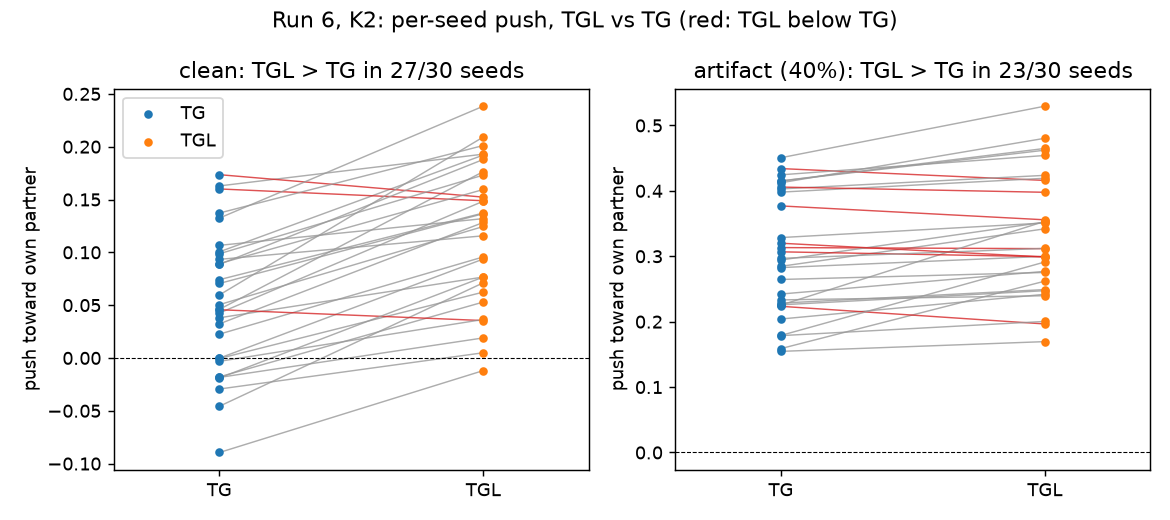

clean K2b: HL 0.067, p_Holm 1.3e-08


In [6]:
def ladder(rate):
    return sorted((c for c in CACHE if c["rate"] == rate), key=lambda c: c["seed"])

clean, artifact = ladder(0.0), ladder(RUN6_PRE["artifact"]["k3Rate"])
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=False)
for ax, entries, name in ((axes[0], clean, "clean"), (axes[1], artifact, "artifact (40%)")):
    tgl = np.array([c["arms"]["TGL"]["push"]["pushMean"] for c in entries])
    tg = np.array([c["arms"]["TG"]["push"]["pushMean"] for c in entries])
    for a, b in zip(tg, tgl):
        ax.plot([0, 1], [a, b], color="0.6" if b > a else "tab:red", lw=0.8, alpha=0.8)
    ax.scatter(np.zeros_like(tg), tg, color="tab:blue", zorder=3, s=14, label="TG")
    ax.scatter(np.ones_like(tgl), tgl, color="tab:orange", zorder=3, s=14, label="TGL")
    ax.axhline(0, color="k", lw=0.6, ls="--")
    ax.set_xticks([0, 1], ["TG", "TGL"])
    ax.set_xlim(-0.4, 1.4)
    ax.set_title(f"{name}: TGL > TG in {(tgl > tg).sum()}/{len(tgl)} seeds")
    ax.set_ylabel("push toward own partner")
axes[0].legend(loc="upper left")
fig.suptitle("Run 6, K2: per-seed push, TGL vs TG (red: TGL below TG)")
fig.tight_layout()
fig.savefig(FIGURES / "k2_push_tgl_vs_tg.png", dpi=130)
plt.close(fig)
display(Image(filename=str(FIGURES / "k2_push_tgl_vs_tg.png")))
print(f"clean K2b: HL {RUN6['tests']['K2b']['hodgesLehmann']:.3f}, "
      f"p_Holm {RUN6['tests']['K2b']['pHolm']:.1e}")

**K3: the ladder.** Target accuracy of the four arms per seed (points joined by seed, boxes
over the 30 seeds) on clean bags and on bags with 40% artifact windows. K3a compares TGL with
TGL-NC on artifact bags; K3b and K3c compare TGL with TG and with TL.

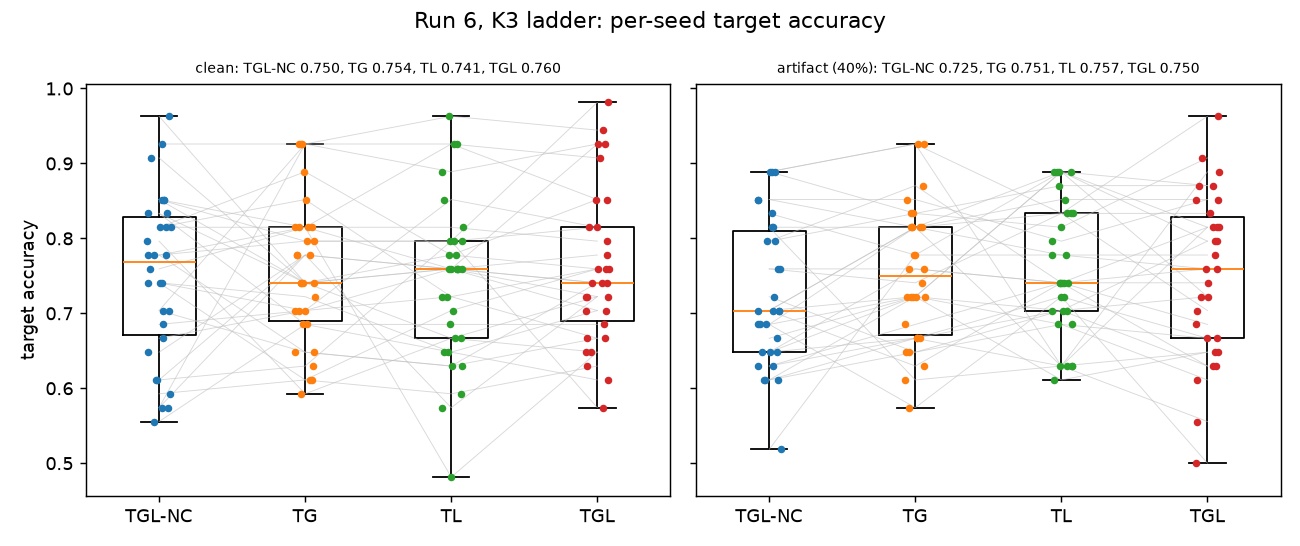

K3a: HL +0.028, p 0.032, p_Holm 0.032
K3b-clean: HL +0.000, p 0.404, p_Holm 0.404
K3c-clean: HL +0.009, p 0.127, p_Holm 0.255
K3b-artifact: HL -0.009, p 0.646, p_Holm 1.000
K3c-artifact: HL -0.009, p 0.705, p_Holm 1.000


In [7]:
ARMS = ["TGL-NC", "TG", "TL", "TGL"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, entries, name in ((axes[0], clean, "clean"), (axes[1], artifact, "artifact (40%)")):
    acc = np.array([[c["arms"][arm]["targetAccuracy"] for arm in ARMS] for c in entries])
    ax.boxplot(acc, positions=range(len(ARMS)), widths=0.5, showfliers=False)
    for row in acc:
        ax.plot(range(len(ARMS)), row, color="0.75", lw=0.5, alpha=0.6)
    rng = np.random.default_rng(0)
    for i in range(len(ARMS)):
        ax.scatter(i + rng.uniform(-0.08, 0.08, len(acc)), acc[:, i], s=10, zorder=3)
    ax.set_xticks(range(len(ARMS)), ARMS)
    ax.set_title(name + ": " + ", ".join(f"{a} {m:.3f}" for a, m in zip(ARMS, acc.mean(0))),
                 fontsize=8)
axes[0].set_ylabel("target accuracy")
fig.suptitle("Run 6, K3 ladder: per-seed target accuracy")
fig.tight_layout()
fig.savefig(FIGURES / "k3_ladder_accuracy.png", dpi=130)
plt.close(fig)
display(Image(filename=str(FIGURES / "k3_ladder_accuracy.png")))
for key in ("K3a", "K3b-clean", "K3c-clean", "K3b-artifact", "K3c-artifact"):
    t = RUN6["tests"][key]
    print(f"{key}: HL {t['hodgesLehmann']:+.3f}, p {t['p']:.3f}, p_Holm {t.get('pHolm', t['p']):.3f}")

## Reading

- H-A and H-B: approved on the toy set against the BN-matched floor; the ranking among the nine
  strategies needs the comparators on EEG.
- H-C: not applicable on the toy set; it states only a ranking claim.
- K1: approved on artifact contamination (the claim of the protocol); donor contamination is
  information on the consensus assumption, outside the claim.
- K2: approved once the scenario gives the local term room; it does not sharpen the end margin
  beyond TG (K2c, information).
- K3: partly approved. Consensus helps under 40% artifacts (K3a); combining the global and local
  terms does not beat either alone (K3b, K3c).
- Every EEG verdict is pending until the full experiments on BALLADEER.